In [1]:
import pandas as pd
import numpy as np
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("german_credit_data.csv", index_col=0)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1000, 10)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [3]:
print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               1000 non-null   int64
 1   Sex               1000 non-null   str  
 2   Job               1000 non-null   int64
 3   Housing           1000 non-null   str  
 4   Saving accounts   817 non-null    str  
 5   Checking account  606 non-null    str  
 6   Credit amount     1000 non-null   int64
 7   Duration          1000 non-null   int64
 8   Purpose           1000 non-null   str  
 9   Risk              1000 non-null   str  
dtypes: int64(4), str(6)
memory usage: 107.3 KB

Column names:
['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']

Data types:
Age                 int64
Sex                   str
Job                 int64
Housing               str
Saving accounts       str
Checking account  

In [4]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

print(missing.sort_values("Missing Percentage", ascending=False))

                  Missing Count  Missing Percentage
Checking account            394                39.4
Saving accounts             183                18.3
Sex                           0                 0.0
Age                           0                 0.0
Housing                       0                 0.0
Job                           0                 0.0
Credit amount                 0                 0.0
Duration                      0                 0.0
Purpose                       0                 0.0
Risk                          0                 0.0


In [5]:
print("Duplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
print(df.nunique())

Duplicate rows: 0

Unique values per column:
Age                  53
Sex                   2
Job                   4
Housing               3
Saving accounts       4
Checking account      3
Credit amount       921
Duration             33
Purpose               8
Risk                  2
dtype: int64


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
Job,1000.0,1.90,0.65,0.0,2.0,2.0,2.00,3.0
Credit amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0


In [7]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Sex ---
Sex
male      690
female    310
Name: count, dtype: int64

--- Housing ---
Housing
own     713
rent    179
free    108
Name: count, dtype: int64

--- Saving accounts ---
Saving accounts
little        603
NaN           183
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64

--- Checking account ---
Checking account
NaN         394
little      274
moderate    269
rich         63
Name: count, dtype: int64

--- Purpose ---
Purpose
car                    337
radio/TV               280
furniture/equipment    181
business                97
education               59
repairs                 22
domestic appliances     12
vacation/others         12
Name: count, dtype: int64

--- Risk ---
Risk
good    700
bad     300
Name: count, dtype: int64


C:\Users\ads2609025\AppData\Local\Temp\1\ipykernel_2304\3607457311.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


In [8]:
print("Risk class counts:")
print(df["Risk"].value_counts(dropna=False))

print("\nRisk class percentages:")
print(
    (df["Risk"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Risk class counts:
Risk
good    700
bad     300
Name: count, dtype: int64

Risk class percentages:
Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64


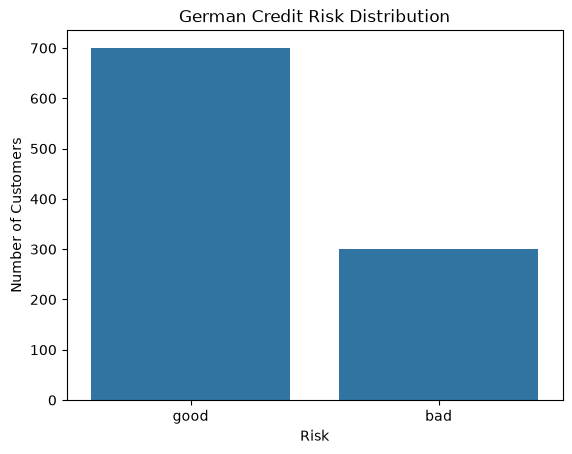

In [9]:
sns.countplot(data=df, x="Risk")
plt.title("German Credit Risk Distribution")
plt.xlabel("Risk")
plt.ylabel("Number of Customers")
plt.show()

In [10]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    print(f"\n--- {col} ---")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Zero values:", (df[col] == 0).sum())


--- Age ---
Minimum: 19
Maximum: 75
Zero values: 0

--- Job ---
Minimum: 0
Maximum: 3
Zero values: 22

--- Credit amount ---
Minimum: 250
Maximum: 18424
Zero values: 0

--- Duration ---
Minimum: 4
Maximum: 72
Zero values: 0


In [11]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original shape: (1000, 10)
Working copy shape: (1000, 10)


In [12]:
account_cols = ["Saving accounts", "Checking account"]

for col in account_cols:
    df_clean[col] = df_clean[col].fillna("unknown")

print("Missing values after preprocessing:")
print(df_clean.isnull().sum())

print("\nSaving accounts:")
print(df_clean["Saving accounts"].value_counts())

print("\nChecking account:")
print(df_clean["Checking account"].value_counts())

Missing values after preprocessing:
Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Risk                0
dtype: int64

Saving accounts:
Saving accounts
little        603
unknown       183
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64

Checking account:
Checking account
unknown     394
little      274
moderate    269
rich         63
Name: count, dtype: int64


In [13]:
print("Shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isnull().sum().sum())

assert df_clean.shape == (1000, 10)
assert df_clean["Risk"].notna().all()
assert df_clean.isnull().sum().sum() == 0

print("\nPreprocessing validation passed!")

Shape: (1000, 10)
Duplicate rows: 0
Missing values: 0

Preprocessing validation passed!


In [14]:
X = df_clean.drop(columns=["Risk"])
y = df_clean["Risk"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (1000, 9)
Target shape: (1000,)

Target distribution:
Risk
good    700
bad     300
Name: count, dtype: int64


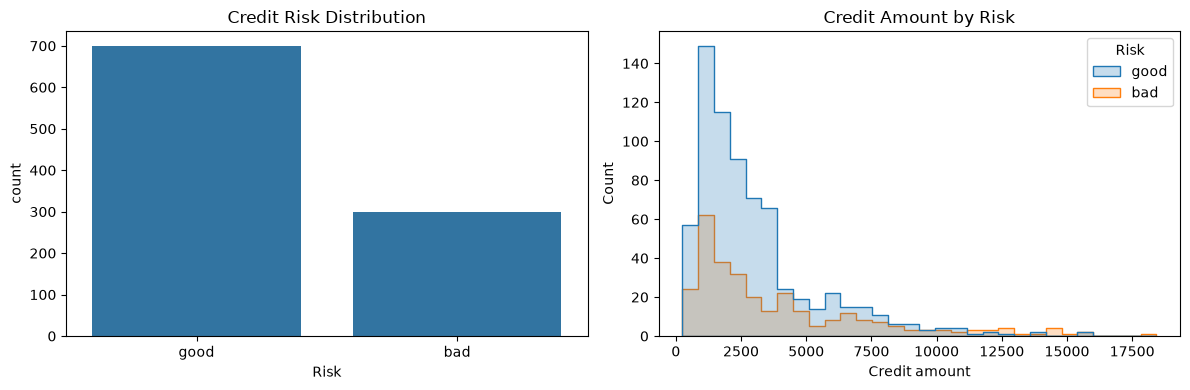

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df_clean, x="Risk", ax=axes[0])
axes[0].set_title("Credit Risk Distribution")

sns.histplot(
    data=df_clean,
    x="Credit amount",
    hue="Risk",
    bins=30,
    element="step",
    stat="count",
    common_norm=False,
    ax=axes[1]
)
axes[1].set_title("Credit Amount by Risk")

plt.tight_layout()
plt.show()

In [16]:
def entropy(y):
    probabilities = pd.Series(y).value_counts(normalize=True)

    return -sum(
        p * np.log2(p)
        for p in probabilities
        if p > 0
    )


print("Target entropy:", round(entropy(y), 4))

Target entropy: 0.8813


In [17]:
def information_gain(data, feature, target):
    parent_entropy = entropy(data[target])
    weighted_child_entropy = 0

    for _, group in data.groupby(feature, dropna=False, observed=True):
        weight = len(group) / len(data)
        weighted_child_entropy += weight * entropy(group[target])

    return parent_entropy - weighted_child_entropy

In [18]:
def gini_impurity(y):
    probabilities = pd.Series(y).value_counts(normalize=True)

    return 1 - sum(p ** 2 for p in probabilities)


print("Target Gini:", round(gini_impurity(y), 4))

Target Gini: 0.42


In [19]:
def gini_reduction(data, feature, target):
    parent_gini = gini_impurity(data[target])
    weighted_child_gini = 0

    for _, group in data.groupby(feature, dropna=False, observed=True):
        weight = len(group) / len(data)
        weighted_child_gini += weight * gini_impurity(group[target])

    return parent_gini - weighted_child_gini

In [20]:
housing_table = pd.crosstab(
    df_clean["Housing"],
    df_clean["Risk"]
)

print(housing_table)

Risk     bad  good
Housing           
free      44    64
own      186   527
rent      70   109


In [21]:
parent_H = entropy(df_clean["Risk"])

housing_details = []

for category, group in df_clean.groupby(
    "Housing", observed=True
):
    counts = group["Risk"].value_counts()

    good = counts.get("good", 0)
    bad = counts.get("bad", 0)

    child_H = entropy(group["Risk"])
    weight = len(group) / len(df_clean)

    housing_details.append({
        "Housing": category,
        "Good": good,
        "Bad": bad,
        "Total": len(group),
        "Weight": weight,
        "Entropy": child_H,
        "Weighted Entropy": weight * child_H
    })

housing_details_df = pd.DataFrame(housing_details)

print(housing_details_df.round(4).to_string(index=False))

weighted_entropy = housing_details_df["Weighted Entropy"].sum()
IG_housing = parent_H - weighted_entropy

print("\nParent entropy:", round(parent_H, 4))
print("Weighted child entropy:", round(weighted_entropy, 4))
print("Information Gain:", round(IG_housing, 4))

Housing  Good  Bad  Total  Weight  Entropy  Weighted Entropy
   free    64   44    108   0.108   0.9751            0.1053
    own   527  186    713   0.713   0.8281            0.5904
   rent   109   70    179   0.179   0.9655            0.1728

Parent entropy: 0.8813
Weighted child entropy: 0.8685
Information Gain: 0.0128


In [22]:
parent_G = gini_impurity(df_clean["Risk"])

housing_details_df["Gini"] = [
    gini_impurity(
        df_clean.loc[
            df_clean["Housing"] == category, "Risk"
        ]
    )
    for category in housing_details_df["Housing"]
]

housing_details_df["Weighted Gini"] = (
    housing_details_df["Weight"] * housing_details_df["Gini"]
)

weighted_gini = housing_details_df["Weighted Gini"].sum()
gini_housing = parent_G - weighted_gini

print(
    housing_details_df[
        ["Housing", "Total", "Gini", "Weighted Gini"]
    ].round(4).to_string(index=False)
)

print("\nParent Gini:", round(parent_G, 4))
print("Weighted child Gini:", round(weighted_gini, 4))
print("Gini reduction:", round(gini_housing, 4))

Housing  Total   Gini  Weighted Gini
   free    108 0.4829         0.0521
    own    713 0.3856         0.2750
   rent    179 0.4763         0.0853

Parent Gini: 0.42
Weighted child Gini: 0.4124
Gini reduction: 0.0076


In [23]:
features_to_compare = [
    "Age",
    "Sex",
    "Job",
    "Housing",
    "Saving accounts",
    "Checking account",
    "Credit amount",
    "Duration",
    "Purpose"
]

comparison = []

for feature in features_to_compare:
    comparison.append({
        "Feature": feature,
        "Information Gain": information_gain(
            df_clean, feature, "Risk"
        ),
        "Gini Reduction": gini_reduction(
            df_clean, feature, "Risk"
        )
    })

comparison_df = pd.DataFrame(comparison)

print(
    comparison_df
    .sort_values("Information Gain", ascending=False)
    .round(4)
    .to_string(index=False)
)

         Feature  Information Gain  Gini Reduction
   Credit amount            0.8238          0.3913
Checking account            0.0947          0.0520
        Duration            0.0634          0.0331
             Age            0.0456          0.0241
 Saving accounts            0.0281          0.0152
         Housing            0.0128          0.0076
         Purpose            0.0100          0.0057
             Sex            0.0040          0.0024
             Job            0.0013          0.0008


In [24]:
def best_numeric_split(data, feature, target):
    values = np.sort(data[feature].unique())

    if len(values) < 2:
        return None

    thresholds = (values[:-1] + values[1:]) / 2
    parent_H = entropy(data[target])
    parent_G = gini_impurity(data[target])

    best_ig = {"score": -1}
    best_gini = {"score": -1}

    for threshold in thresholds:
        left = data[data[feature] <= threshold]
        right = data[data[feature] > threshold]

        weighted_H = (
            len(left) / len(data) * entropy(left[target])
            + len(right) / len(data) * entropy(right[target])
        )

        weighted_G = (
            len(left) / len(data) * gini_impurity(left[target])
            + len(right) / len(data) * gini_impurity(right[target])
        )

        ig = parent_H - weighted_H
        gini_gain_value = parent_G - weighted_G

        if ig > best_ig["score"]:
            best_ig = {
                "threshold": threshold,
                "score": ig
            }

        if gini_gain_value > best_gini["score"]:
            best_gini = {
                "threshold": threshold,
                "score": gini_gain_value
            }

    return {
        "Feature": feature,
        "Best IG Threshold": best_ig["threshold"],
        "Best Information Gain": best_ig["score"],
        "Best Gini Threshold": best_gini["threshold"],
        "Best Gini Reduction": best_gini["score"]
    }


numeric_results = pd.DataFrame([
    best_numeric_split(df_clean, feature, "Risk")
    for feature in ["Age", "Job", "Credit amount", "Duration"]
])

print(
    numeric_results
    .sort_values("Best Information Gain", ascending=False)
    .round(4)
    .to_string(index=False)
)

      Feature  Best IG Threshold  Best Information Gain  Best Gini Threshold  Best Gini Reduction
     Duration               15.5                 0.0233                 34.5               0.0136
Credit amount             3913.5                 0.0187               3913.5               0.0113
          Age               25.5                 0.0113                 25.5               0.0069
          Job                2.5                 0.0012                  2.5               0.0007


In [25]:
TARGET = "Risk"

FEATURES = [
    "Age",
    "Sex",
    "Job",
    "Housing",
    "Saving accounts",
    "Checking account",
    "Credit amount",
    "Duration",
    "Purpose"
]

MAX_DEPTH = 3
MIN_SAMPLES_SPLIT = 2
MIN_GAIN = 1e-10

print("Maximum depth:", MAX_DEPTH)
print("Number of features:", len(FEATURES))
print("Target classes:", sorted(df_clean[TARGET].unique()))

Maximum depth: 3
Number of features: 9
Target classes: ['bad', 'good']


In [26]:
def find_best_split(data, features, target, criterion="entropy"):
    parent_impurity = (
        entropy(data[target])
        if criterion == "entropy"
        else gini_impurity(data[target])
    )

    best_split = None
    best_score = 0.0

    for feature in features:
        values = data[feature].dropna().unique()

        if len(values) < 2:
            continue

        is_numeric = pd.api.types.is_numeric_dtype(data[feature])

        if is_numeric:
            sorted_values = np.sort(values.astype(float))
            candidates = (sorted_values[:-1] + sorted_values[1:]) / 2
            split_type = "numeric"
        else:
            candidates = values
            split_type = "categorical"

        for candidate in candidates:
            if split_type == "numeric":
                left_mask = data[feature] <= candidate
            else:
                left_mask = data[feature] == candidate

            left = data.loc[left_mask]
            right = data.loc[~left_mask]

            if len(left) == 0 or len(right) == 0:
                continue

            impurity_fn = (
                entropy if criterion == "entropy"
                else gini_impurity
            )

            weighted_impurity = (
                len(left) / len(data) * impurity_fn(left[target])
                + len(right) / len(data) * impurity_fn(right[target])
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_score:
                best_score = gain
                best_split = {
                    "feature": feature,
                    "split_type": split_type,
                    "value": candidate,
                    "gain": gain,
                    "left": left.index.tolist(),
                    "right": right.index.tolist()
                }

    return best_split

In [27]:
def majority_class(y):
    return y.value_counts().idxmax()


def build_tree(
    data,
    features,
    target,
    depth=0,
    max_depth=3,
    min_samples_split=2,
    criterion="entropy"
):
    # Prediction for this node if it becomes a leaf
    prediction = majority_class(data[target])

    # Stop conditions
    if (
        data[target].nunique() == 1
        or depth >= max_depth
        or len(data) < min_samples_split
    ):
        return {
            "type": "leaf",
            "prediction": prediction,
            "samples": len(data),
            "counts": data[target].value_counts().to_dict()
        }

    split = find_best_split(
        data, features, target, criterion=criterion
    )

    # Stop if no positive-gain split exists
    if split is None or split["gain"] <= MIN_GAIN:
        return {
            "type": "leaf",
            "prediction": prediction,
            "samples": len(data),
            "counts": data[target].value_counts().to_dict()
        }

    if split["split_type"] == "numeric":
        left_mask = data[split["feature"]] <= split["value"]
    else:
        left_mask = data[split["feature"]] == split["value"]

    left_data = data.loc[left_mask]
    right_data = data.loc[~left_mask]

    return {
        "type": "node",
        "feature": split["feature"],
        "split_type": split["split_type"],
        "value": split["value"],
        "gain": split["gain"],
        "samples": len(data),
        "counts": data[target].value_counts().to_dict(),
        "left": build_tree(
            left_data, features, target,
            depth + 1, max_depth,
            min_samples_split, criterion
        ),
        "right": build_tree(
            right_data, features, target,
            depth + 1, max_depth,
            min_samples_split, criterion
        )
    }

In [28]:
tree = build_tree(
    data=df_clean,
    features=FEATURES,
    target=TARGET,
    depth=0,
    max_depth=MAX_DEPTH,
    min_samples_split=MIN_SAMPLES_SPLIT,
    criterion="entropy"
)

print("Decision tree trained successfully!")

Decision tree trained successfully!


In [29]:
def print_tree(node, indent=""):
    if node["type"] == "leaf":
        print(
            f"{indent}PREDICT {node['prediction']} "
            f"(samples={node['samples']}, "
            f"class_counts={node['counts']})"
        )
        return

    if node["split_type"] == "numeric":
        condition = f"{node['feature']} <= {node['value']:.2f}"
    else:
        condition = f'{node["feature"]} == "{node["value"]}"'

    print(
        f"{indent}IF {condition} "
        f"[Information Gain={node['gain']:.4f}, "
        f"samples={node['samples']}]"
    )

    print(f"{indent}  TRUE:")
    print_tree(node["left"], indent + "    ")

    print(f"{indent}  FALSE:")
    print_tree(node["right"], indent + "    ")


print_tree(tree)

IF Checking account == "unknown" [Information Gain=0.0819, samples=1000]
  TRUE:
    IF Credit amount <= 3891.00 [Information Gain=0.0226, samples=394]
      TRUE:
        IF Age <= 22.50 [Information Gain=0.0232, samples=301]
          TRUE:
            PREDICT good (samples=13, class_counts={'good': 8, 'bad': 5})
          FALSE:
            PREDICT good (samples=288, class_counts={'good': 268, 'bad': 20})
      FALSE:
        IF Purpose == "business" [Information Gain=0.0404, samples=93]
          TRUE:
            PREDICT good (samples=15, class_counts={'good': 8, 'bad': 7})
          FALSE:
            PREDICT good (samples=78, class_counts={'good': 64, 'bad': 14})
  FALSE:
    IF Duration <= 22.50 [Information Gain=0.0303, samples=606]
      TRUE:
        IF Duration <= 11.50 [Information Gain=0.0202, samples=349]
          TRUE:
            PREDICT good (samples=103, class_counts={'good': 81, 'bad': 22})
          FALSE:
            PREDICT good (samples=246, class_counts={'good

In [30]:
def predict_one(node, sample):
    while node["type"] != "leaf":
        feature = node["feature"]
        value = node["value"]

        if node["split_type"] == "numeric":
            go_left = sample[feature] <= value
        else:
            go_left = sample[feature] == value

        node = node["left"] if go_left else node["right"]

    return node["prediction"]

In [31]:
def trace_prediction(node, sample):
    path = []

    while node["type"] != "leaf":
        feature = node["feature"]
        value = node["value"]

        if node["split_type"] == "numeric":
            condition = f"{feature} <= {value:.2f}"
            go_left = sample[feature] <= value
        else:
            condition = f'{feature} == "{value}"'
            go_left = sample[feature] == value

        result = "TRUE" if go_left else "FALSE"
        path.append(f"{condition} -> {result}")

        node = node["left"] if go_left else node["right"]

    path.append(f"Leaf prediction -> {node['prediction']}")
    return path

In [32]:
sample_indices = [0, 500, 999]

for idx in sample_indices:
    sample = df_clean.loc[idx]

    print("\n" + "=" * 60)
    print(f"Customer index: {idx}")
    print("Actual risk:", sample[TARGET])

    print("\nDecision path:")
    for step_number, step in enumerate(
        trace_prediction(tree, sample), start=1
    ):
        print(f"{step_number}. {step}")

    prediction = predict_one(tree, sample)
    print("\nPredicted risk:", prediction)
    print("Correct prediction:", prediction == sample[TARGET])


Customer index: 0
Actual risk: good

Decision path:
1. Checking account == "unknown" -> FALSE
2. Duration <= 22.50 -> TRUE
3. Duration <= 11.50 -> TRUE
4. Leaf prediction -> good

Predicted risk: good
Correct prediction: True

Customer index: 500
Actual risk: bad

Decision path:
1. Checking account == "unknown" -> FALSE
2. Duration <= 22.50 -> FALSE
3. Saving accounts == "little" -> TRUE
4. Leaf prediction -> bad

Predicted risk: bad
Correct prediction: True

Customer index: 999
Actual risk: good

Decision path:
1. Checking account == "unknown" -> FALSE
2. Duration <= 22.50 -> FALSE
3. Saving accounts == "little" -> FALSE
4. Leaf prediction -> good

Predicted risk: good
Correct prediction: True


In [33]:
def get_tree_depth(node):
    if node["type"] == "leaf":
        return 0

    return 1 + max(
        get_tree_depth(node["left"]),
        get_tree_depth(node["right"])
    )


print("Maximum tree depth:", get_tree_depth(tree))
print("Configured maximum depth:", MAX_DEPTH)

assert get_tree_depth(tree) <= MAX_DEPTH

Maximum tree depth: 3
Configured maximum depth: 3


In [34]:
gini_tree = build_tree(
    data=df_clean,
    features=FEATURES,
    target=TARGET,
    max_depth=MAX_DEPTH,
    min_samples_split=MIN_SAMPLES_SPLIT,
    criterion="gini"
)

print("Entropy-based tree root:")
print_tree(tree)

print("\nGini-based tree root:")
print_tree(gini_tree)

Entropy-based tree root:
IF Checking account == "unknown" [Information Gain=0.0819, samples=1000]
  TRUE:
    IF Credit amount <= 3891.00 [Information Gain=0.0226, samples=394]
      TRUE:
        IF Age <= 22.50 [Information Gain=0.0232, samples=301]
          TRUE:
            PREDICT good (samples=13, class_counts={'good': 8, 'bad': 5})
          FALSE:
            PREDICT good (samples=288, class_counts={'good': 268, 'bad': 20})
      FALSE:
        IF Purpose == "business" [Information Gain=0.0404, samples=93]
          TRUE:
            PREDICT good (samples=15, class_counts={'good': 8, 'bad': 7})
          FALSE:
            PREDICT good (samples=78, class_counts={'good': 64, 'bad': 14})
  FALSE:
    IF Duration <= 22.50 [Information Gain=0.0303, samples=606]
      TRUE:
        IF Duration <= 11.50 [Information Gain=0.0202, samples=349]
          TRUE:
            PREDICT good (samples=103, class_counts={'good': 81, 'bad': 22})
          FALSE:
            PREDICT good (samples

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [36]:
X = df_clean.drop(columns=["Risk"]).copy()
y = df_clean["Risk"].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nDataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Numerical features: ['Age', 'Job', 'Credit amount', 'Duration']
Categorical features: ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

Dataset shape: (1000, 9)

Target distribution:
Risk
good    700
bad     300
Name: count, dtype: int64


In [37]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining risk distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation risk distribution:")
print(y_val.value_counts(normalize=True).round(3))

Training samples: 600
Validation samples: 200
Test samples: 200

Training risk distribution:
Risk
good    0.7
bad     0.3
Name: proportion, dtype: float64

Validation risk distribution:
Risk
good    0.7
bad     0.3
Name: proportion, dtype: float64


In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    verbose_feature_names_out=False
)

depths = [2, 4, 6, 10, None]

models = {}
results = []

for depth in depths:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("tree", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    models[depth] = model

    results.append({
        "max_depth": str(depth),
        "training_accuracy": train_acc,
        "validation_accuracy": val_acc,
        "accuracy_gap": train_acc - val_acc,
        "actual_tree_depth": model.named_steps["tree"].get_depth(),
        "number_of_leaves": model.named_steps["tree"].get_n_leaves()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

max_depth  training_accuracy  validation_accuracy  accuracy_gap  actual_tree_depth  number_of_leaves
        2             0.7000                0.700        0.0000                  2                 4
        4             0.7733                0.740        0.0333                  4                14
        6             0.8200                0.725        0.0950                  6                40
       10             0.9333                0.660        0.2733                 10               108
     None             1.0000                0.695        0.3050                 17               143


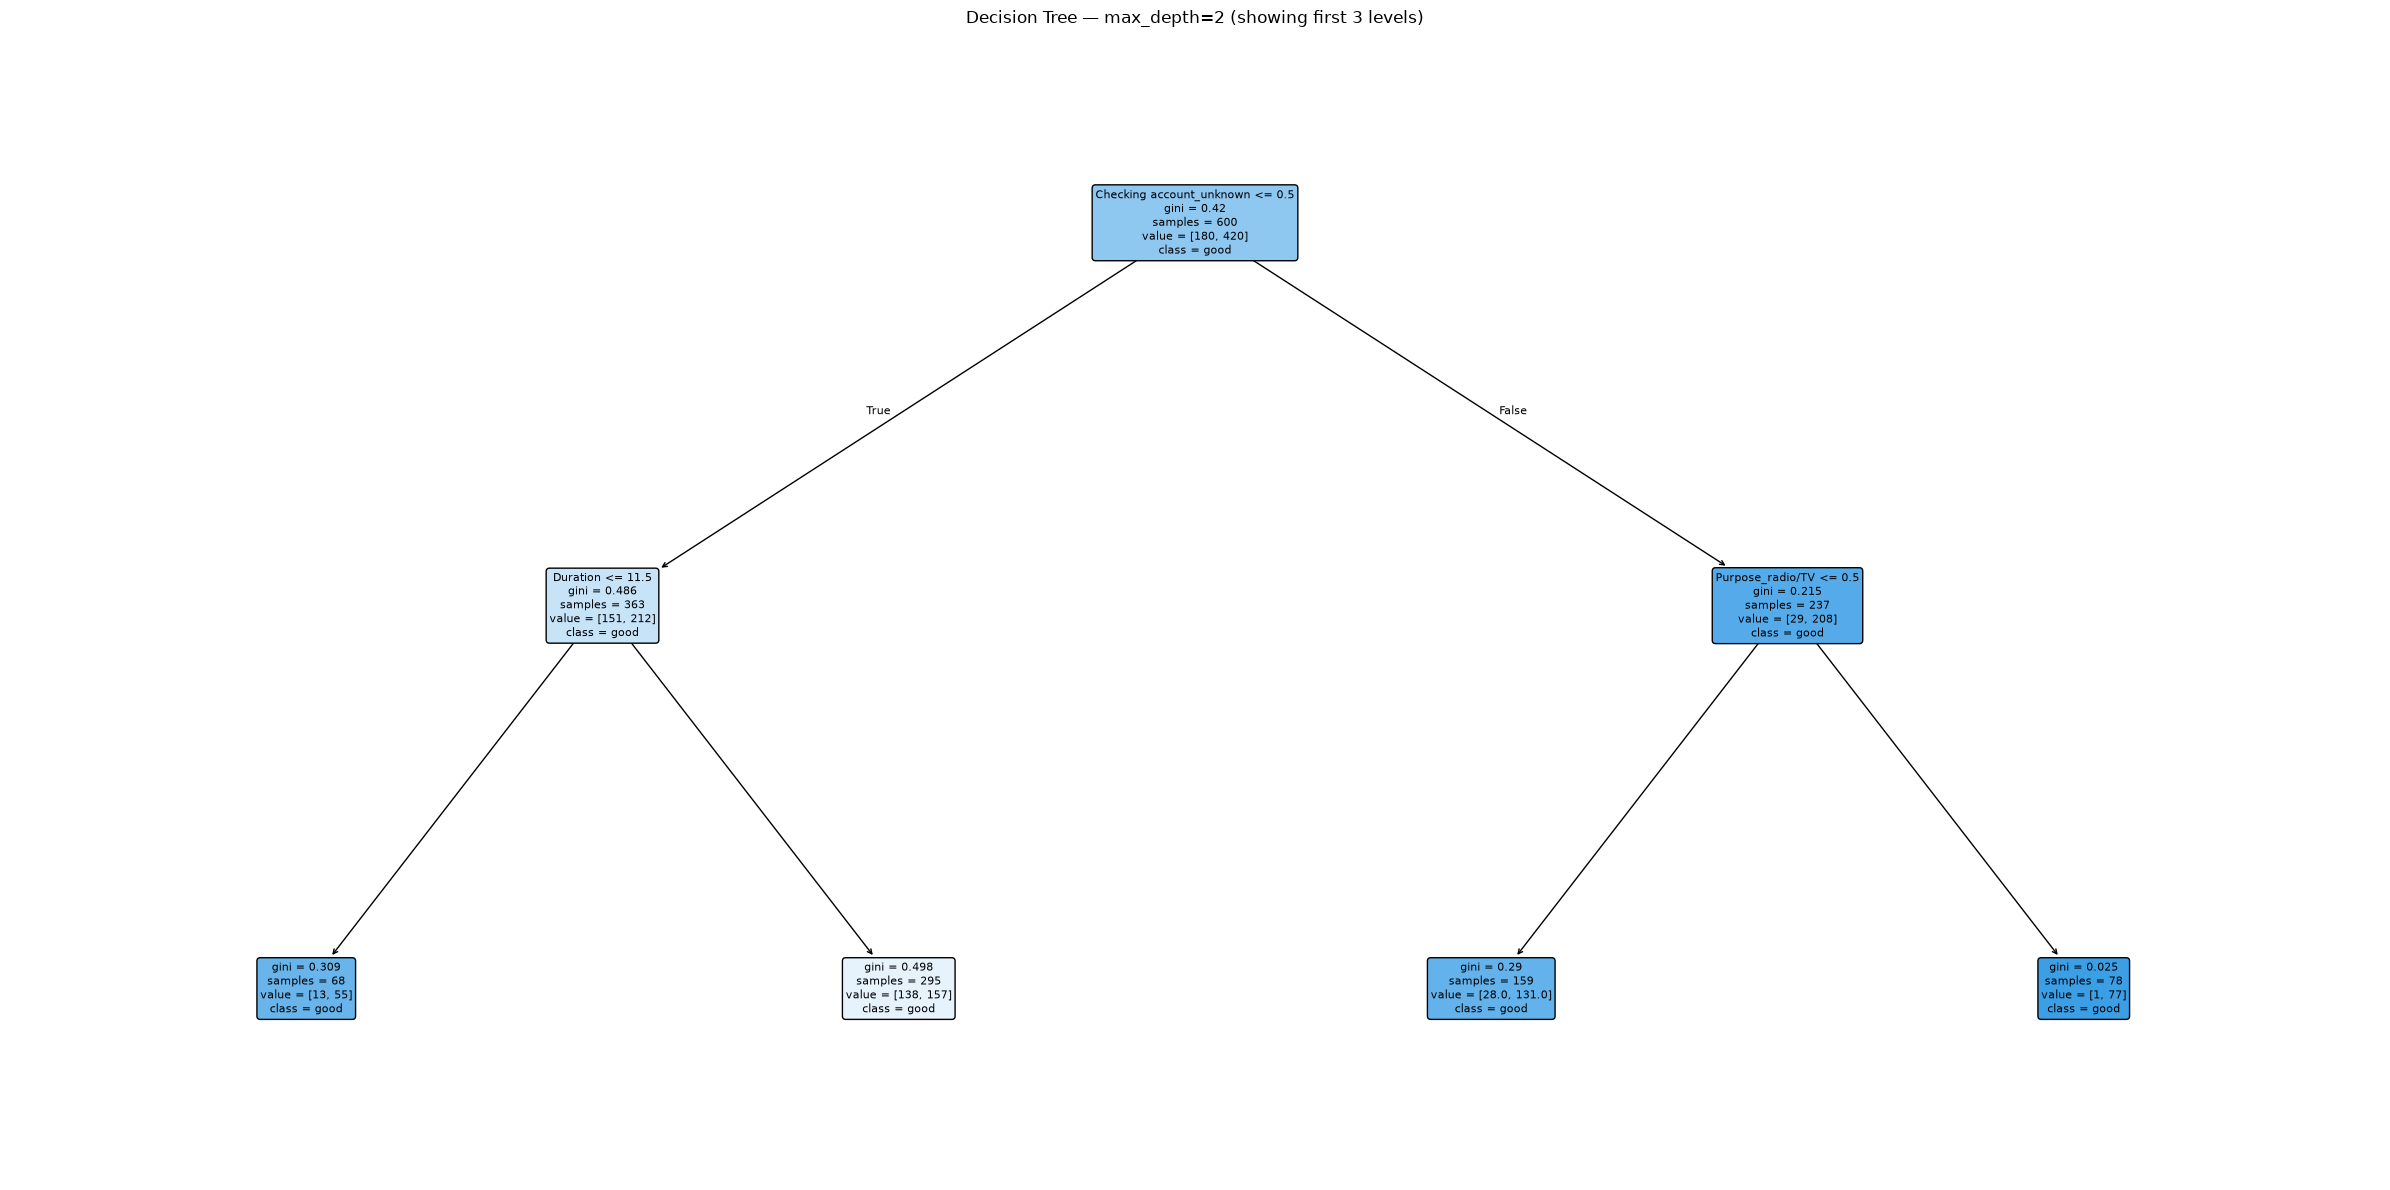

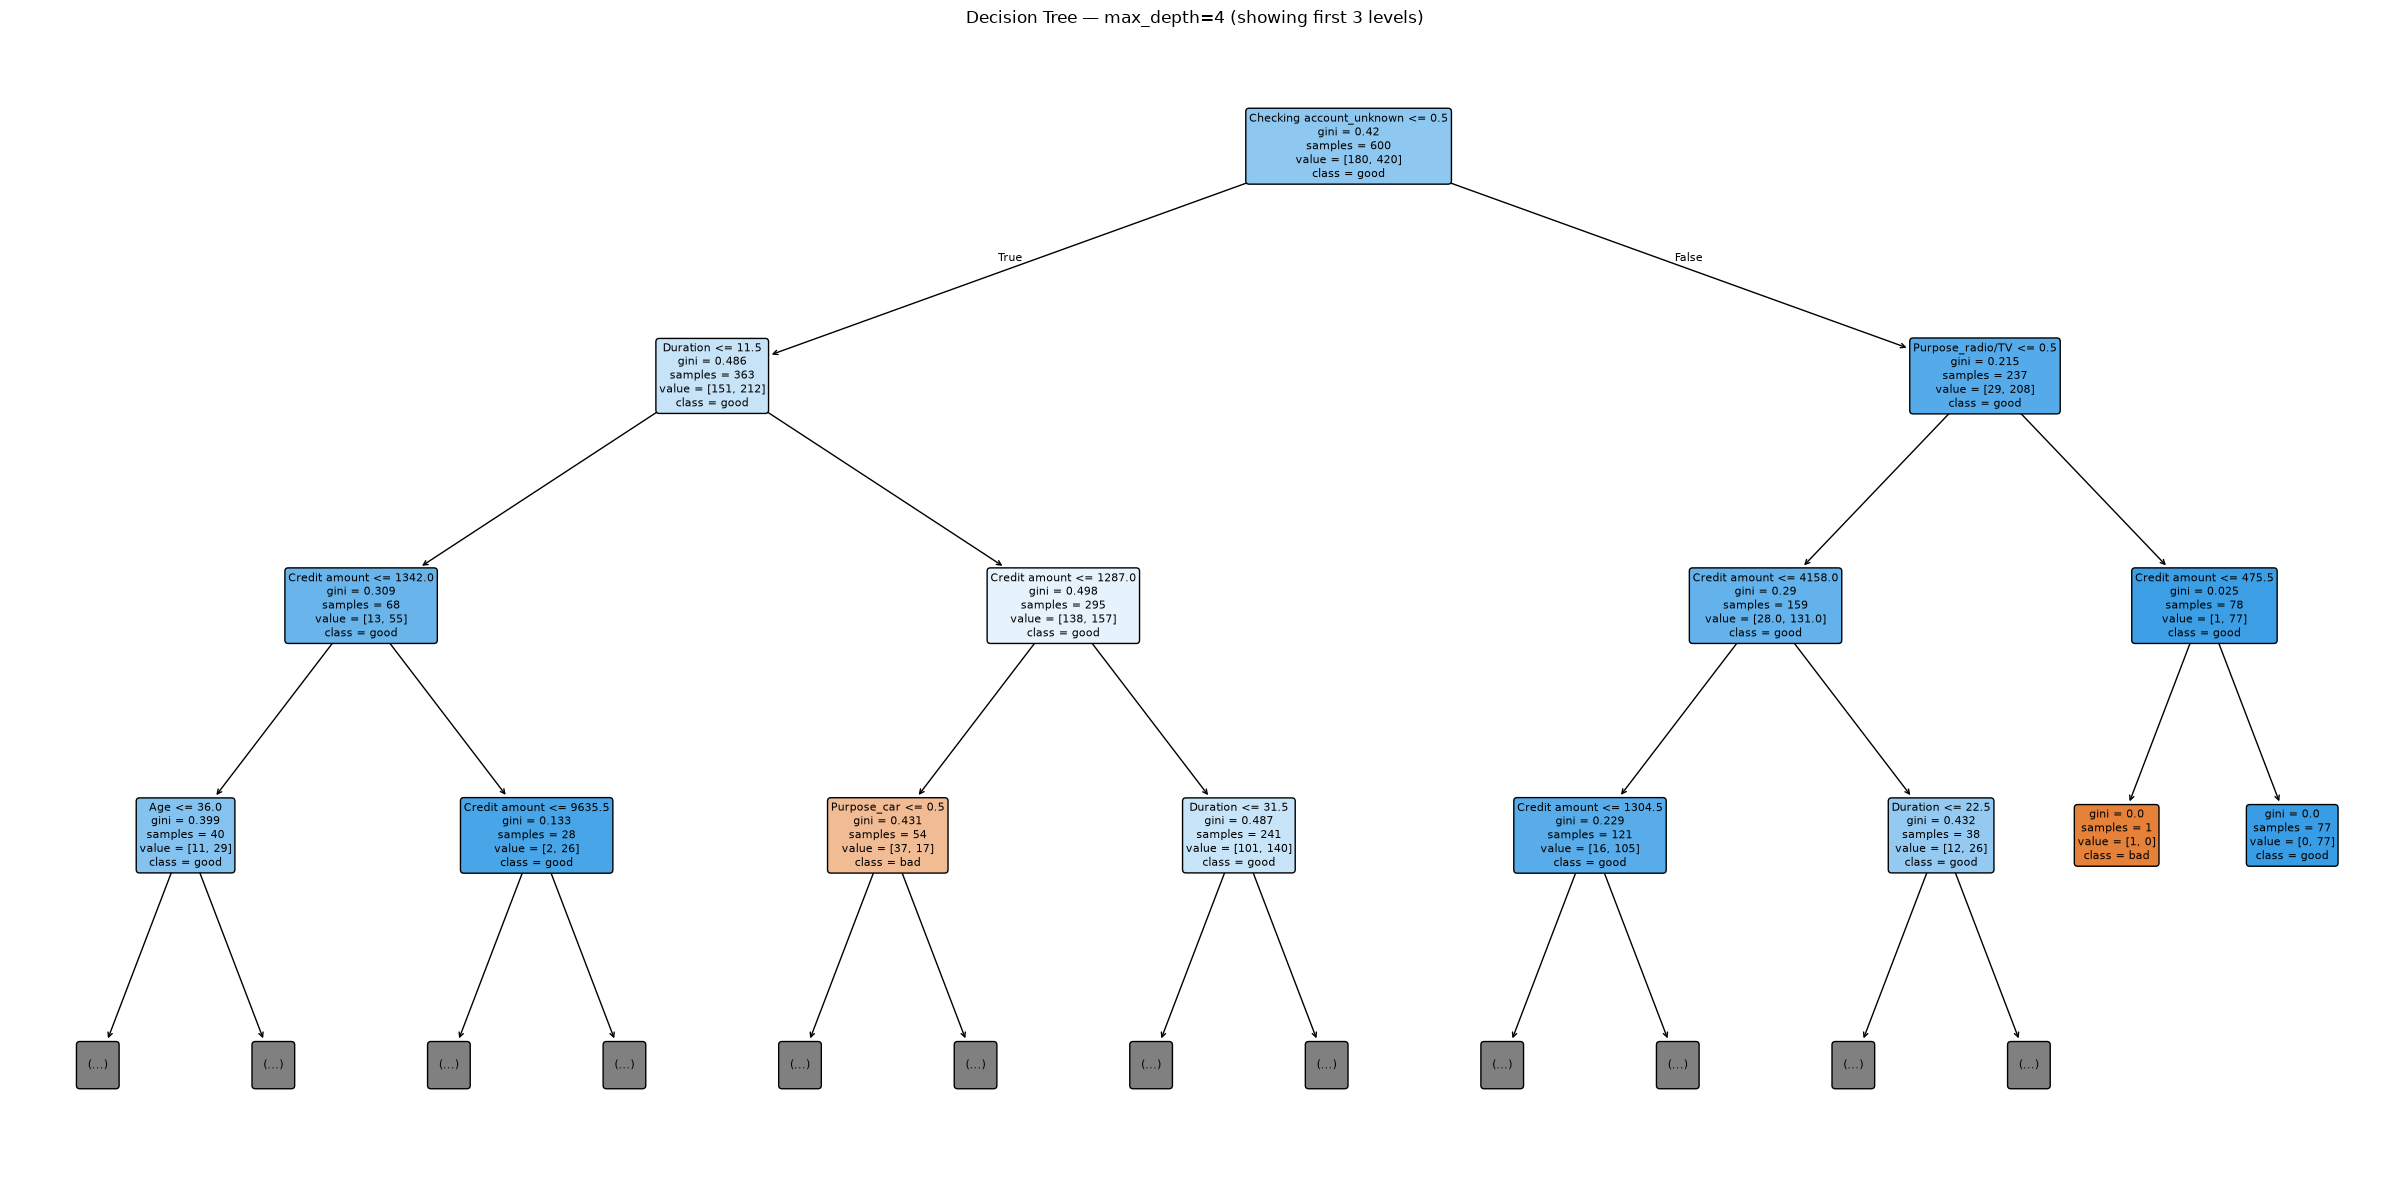

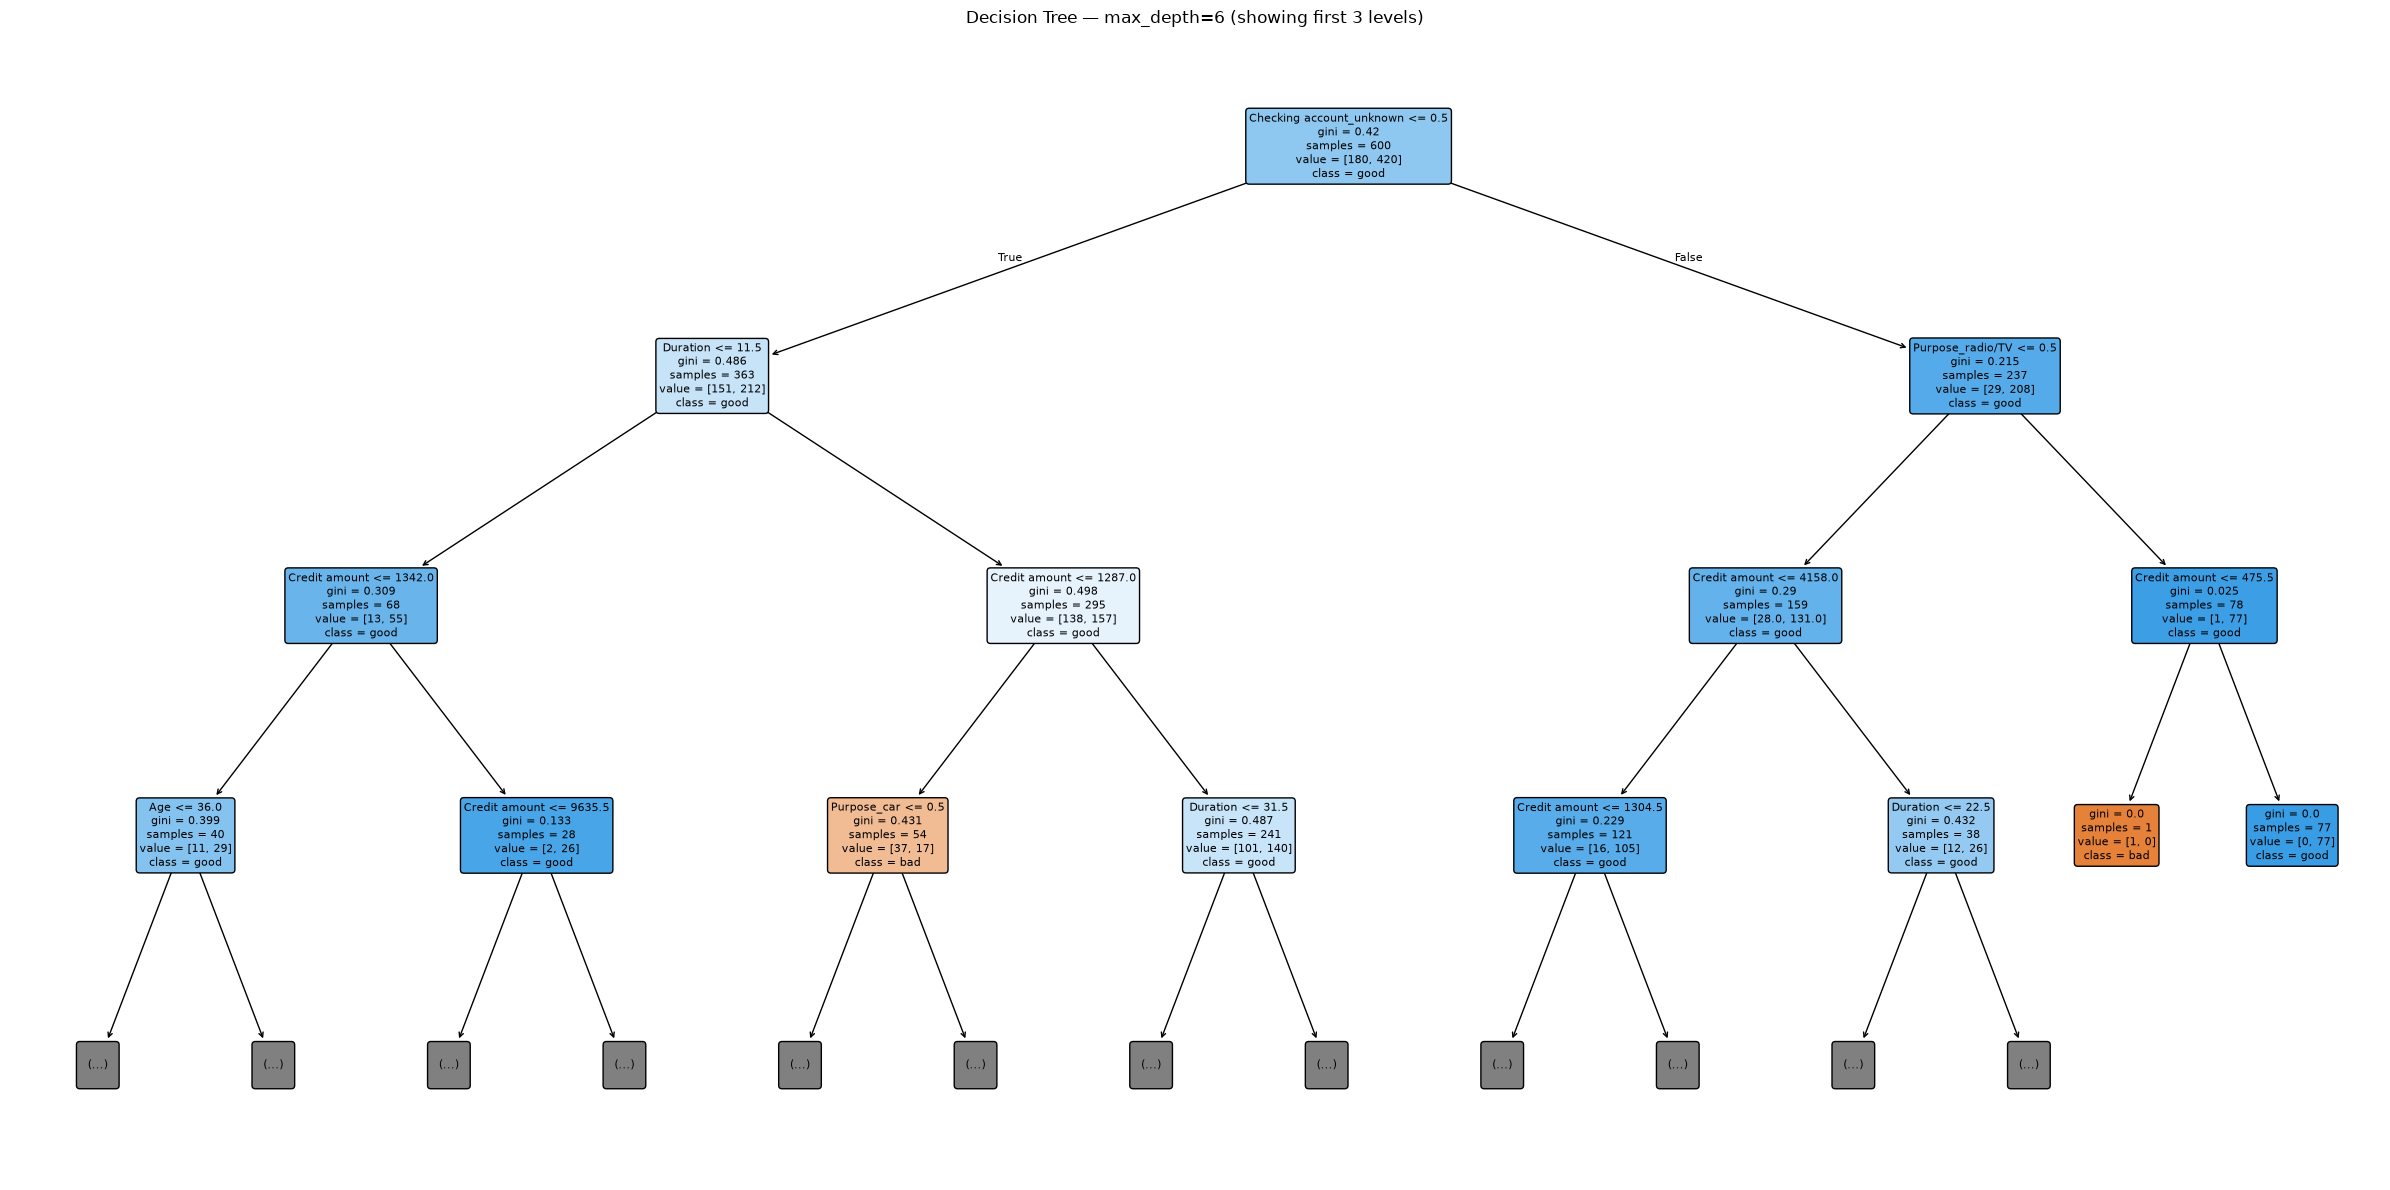

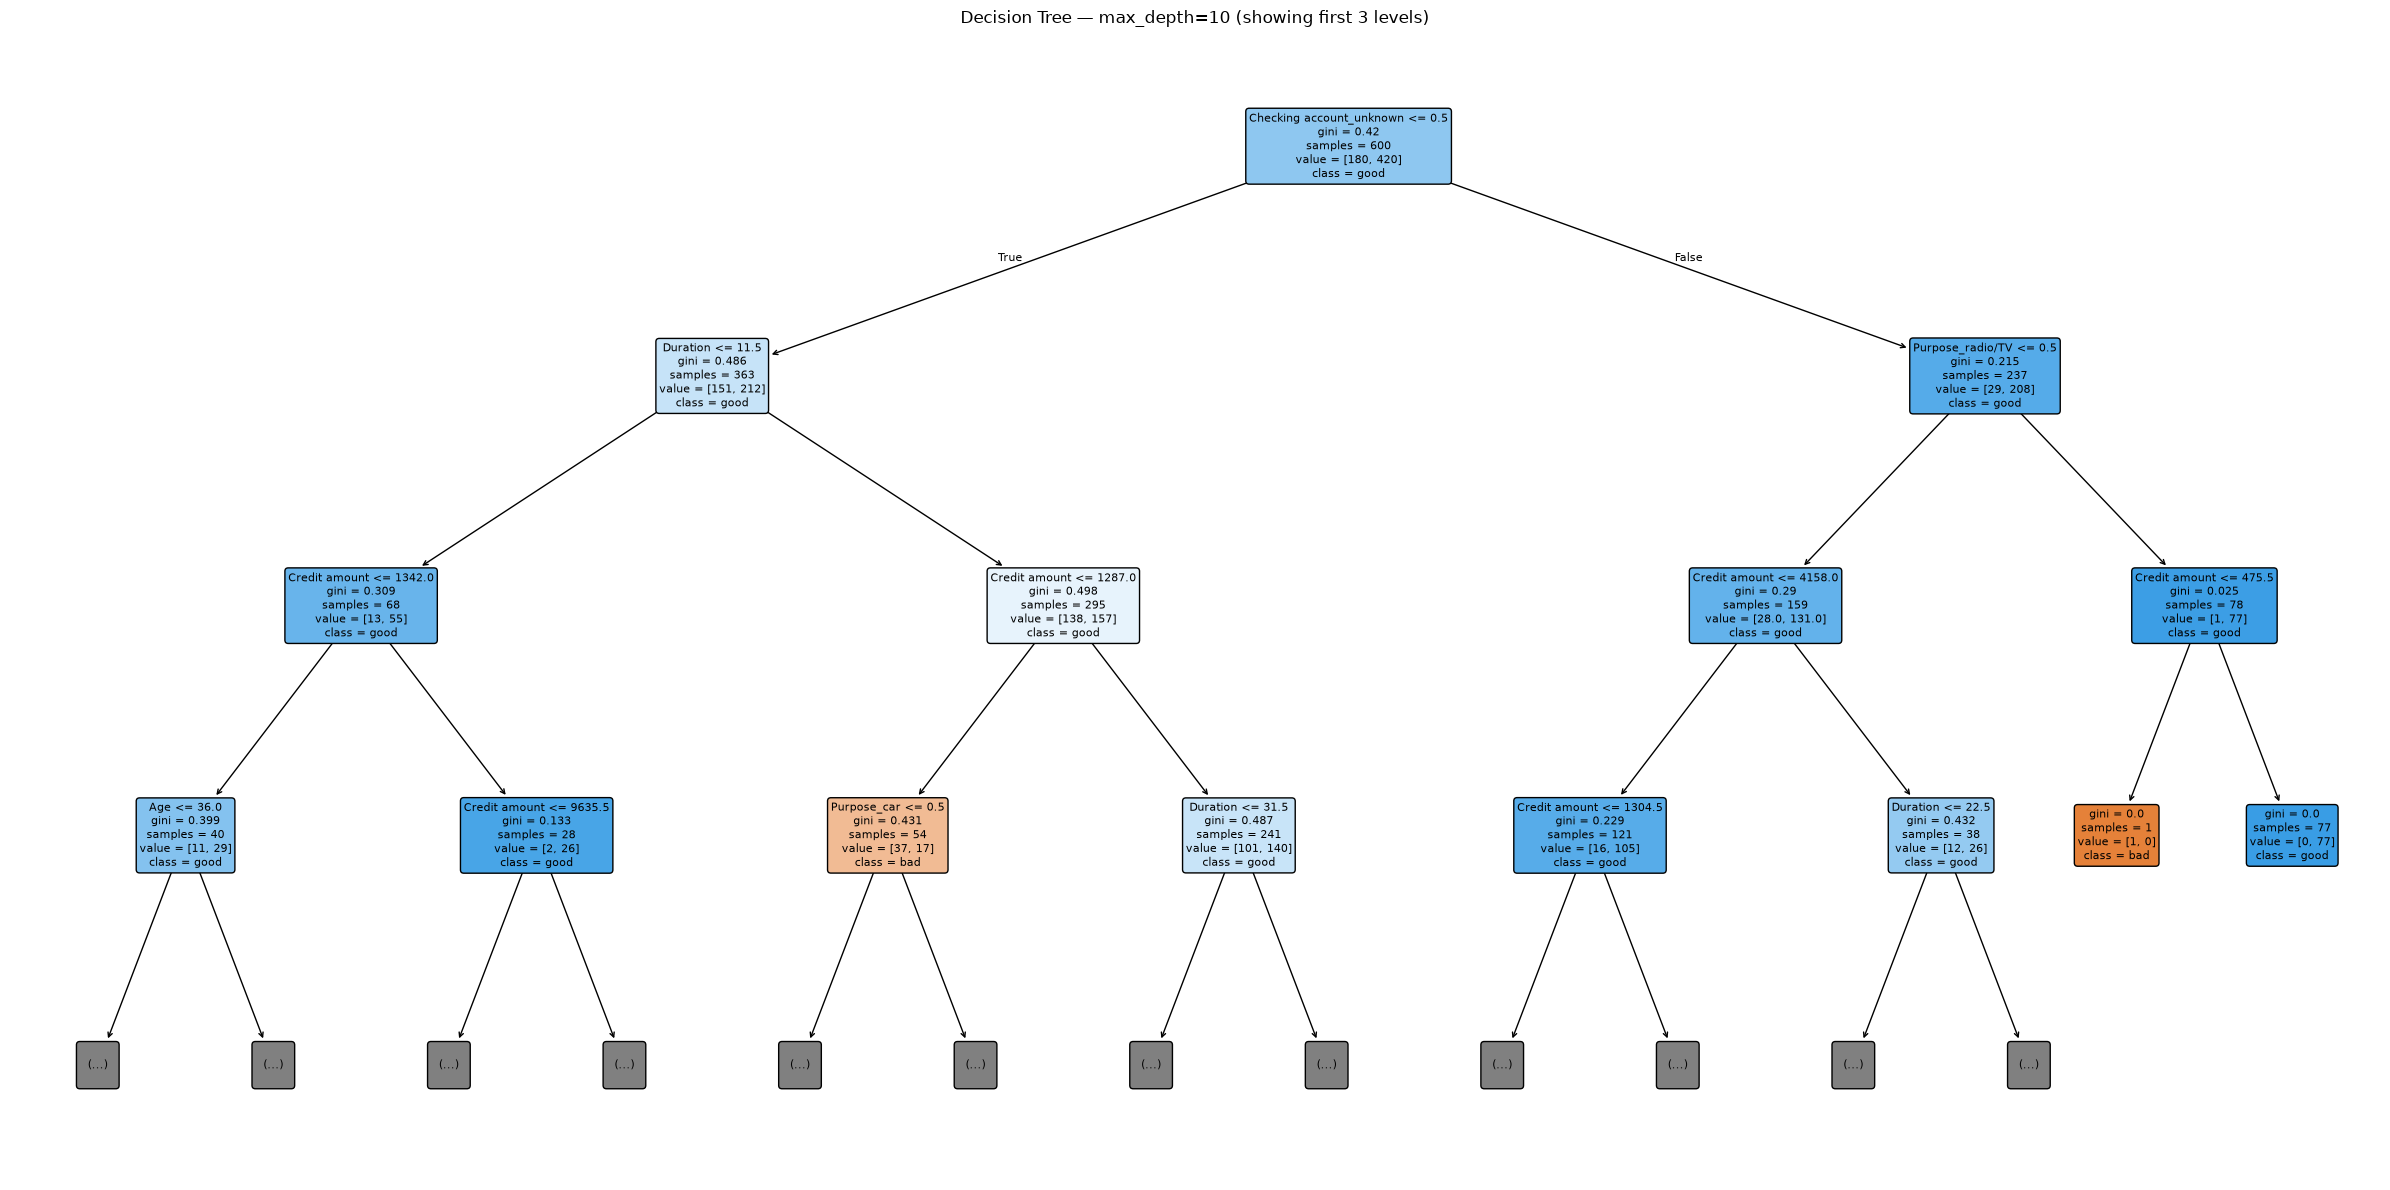

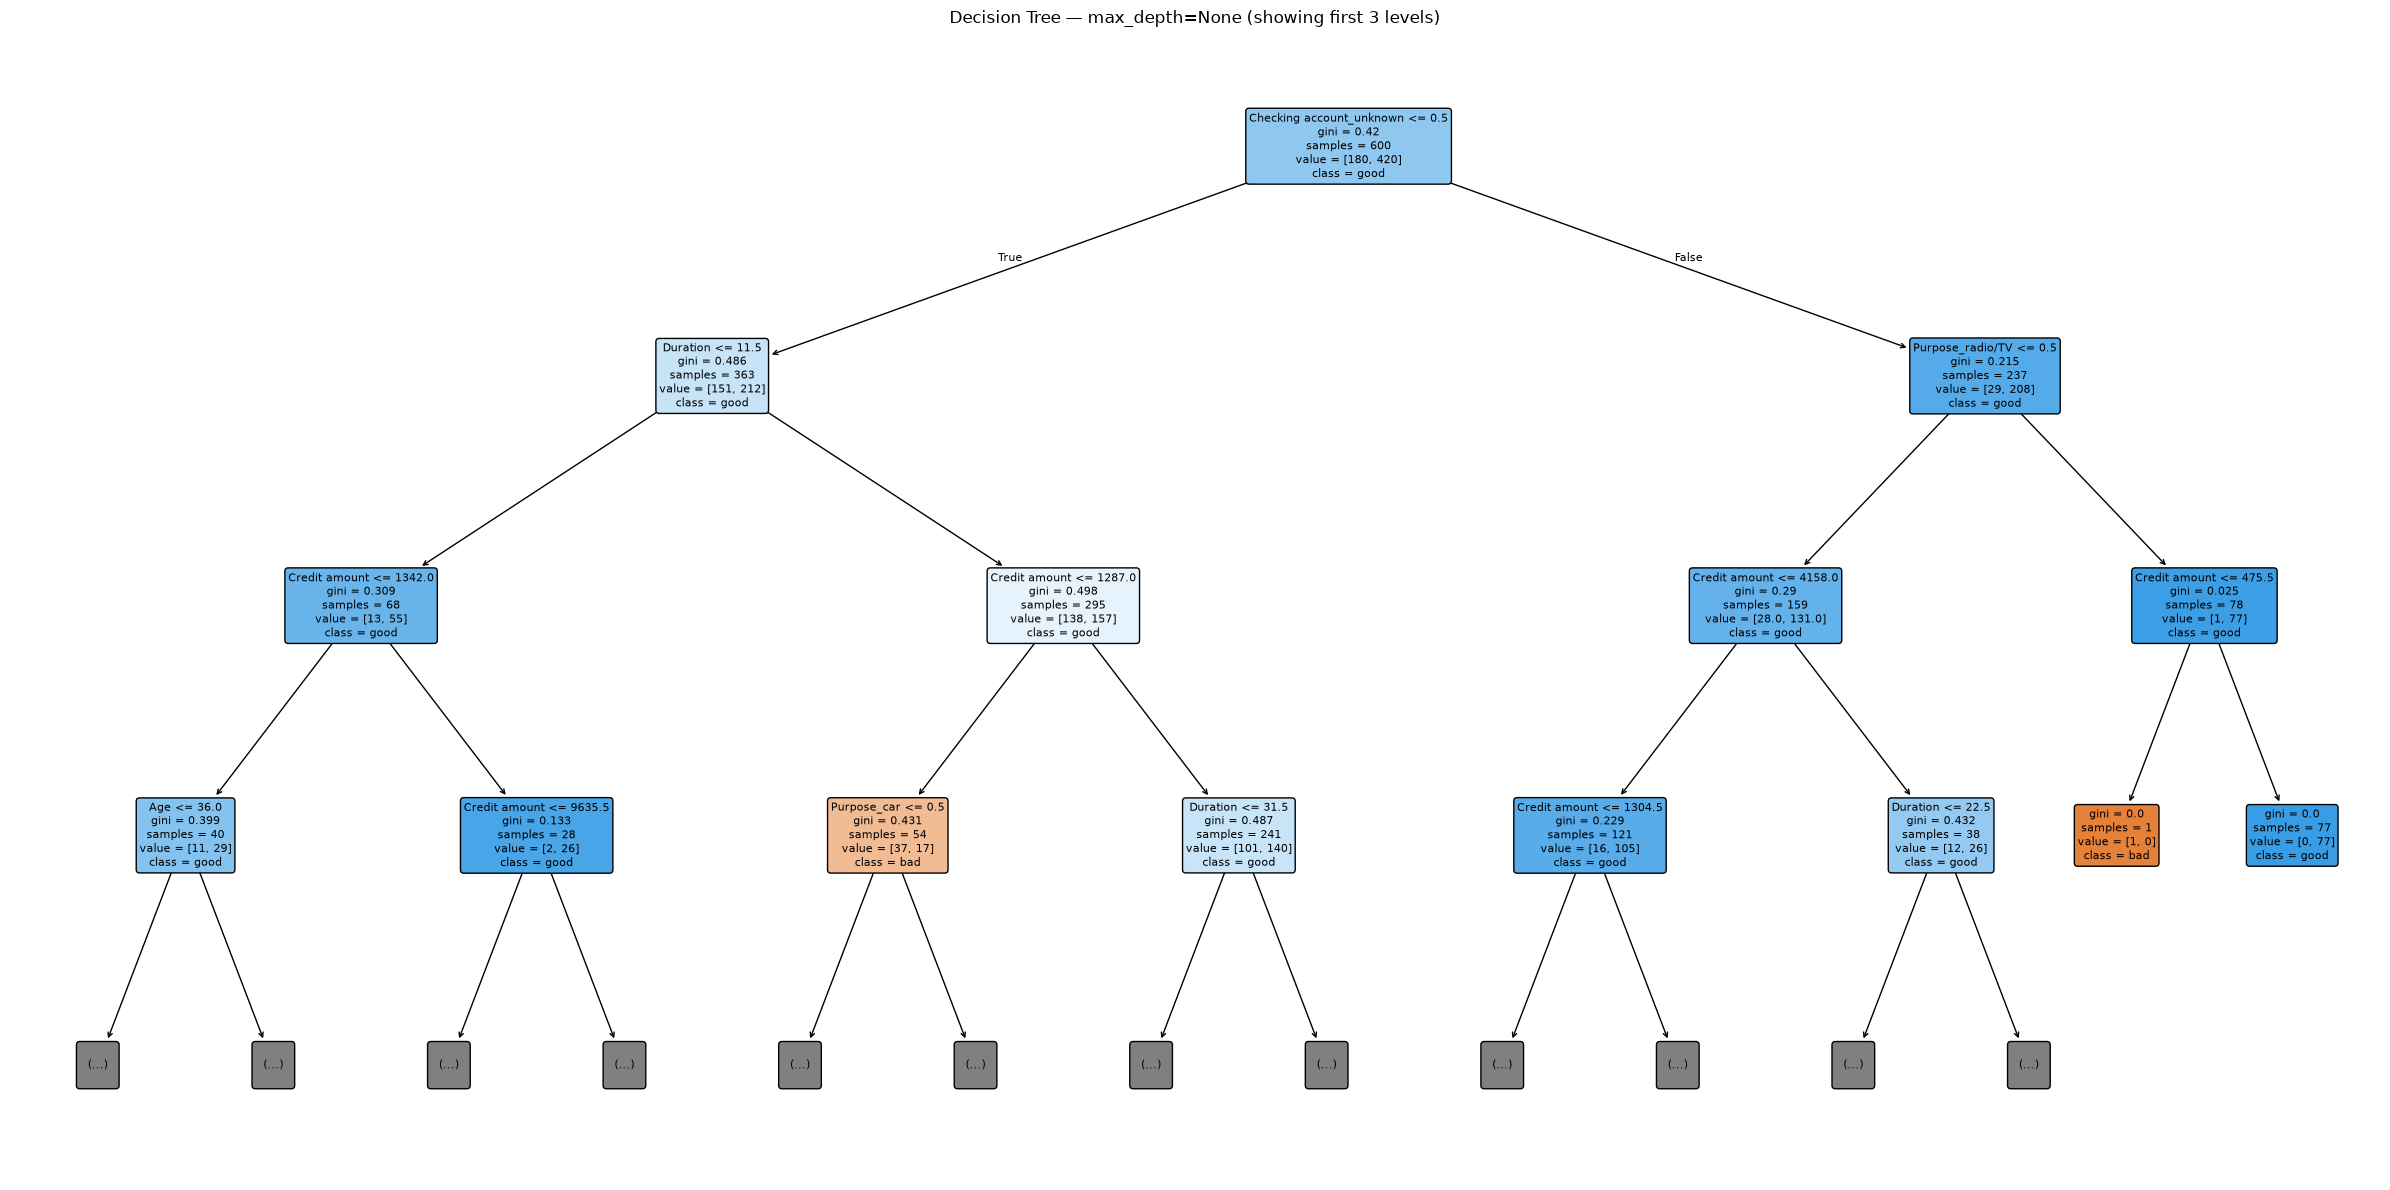

In [39]:
for depth, model in models.items():
    fitted_preprocessor = model.named_steps["preprocessor"]
    classifier = model.named_steps["tree"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    class_names = [str(c) for c in classifier.classes_]

    fig, ax = plt.subplots(figsize=(24, 12))

    plot_tree(
        classifier,
        feature_names=feature_names,
        class_names=class_names,
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=8,
        ax=ax
    )

    ax.set_title(
        f"Decision Tree — max_depth={depth} "
        f"(showing first 3 levels)"
    )

    plt.tight_layout()
    plt.show()

In [40]:
root_rows = []

for depth, model in models.items():
    classifier = model.named_steps["tree"]
    feature_names = model.named_steps["preprocessor"].get_feature_names_out()

    root_feature_index = classifier.tree_.feature[0]
    root_threshold = classifier.tree_.threshold[0]

    root_feature = feature_names[root_feature_index]

    root_rows.append({
        "max_depth": str(depth),
        "root_feature": root_feature,
        "root_threshold": root_threshold,
        "root_gini": classifier.tree_.impurity[0],
        "root_samples": classifier.tree_.n_node_samples[0],
        "root_feature_importance": classifier.feature_importances_[
            root_feature_index
        ]
    })

root_df = pd.DataFrame(root_rows)

print(root_df.round(4).to_string(index=False))

max_depth             root_feature  root_threshold  root_gini  root_samples  root_feature_importance
        2 Checking account_unknown             0.5       0.42           600                   0.6873
        4 Checking account_unknown             0.5       0.42           600                   0.3671
        6 Checking account_unknown             0.5       0.42           600                   0.2209
       10 Checking account_unknown             0.5       0.42           600                   0.1239
     None Checking account_unknown             0.5       0.42           600                   0.0981


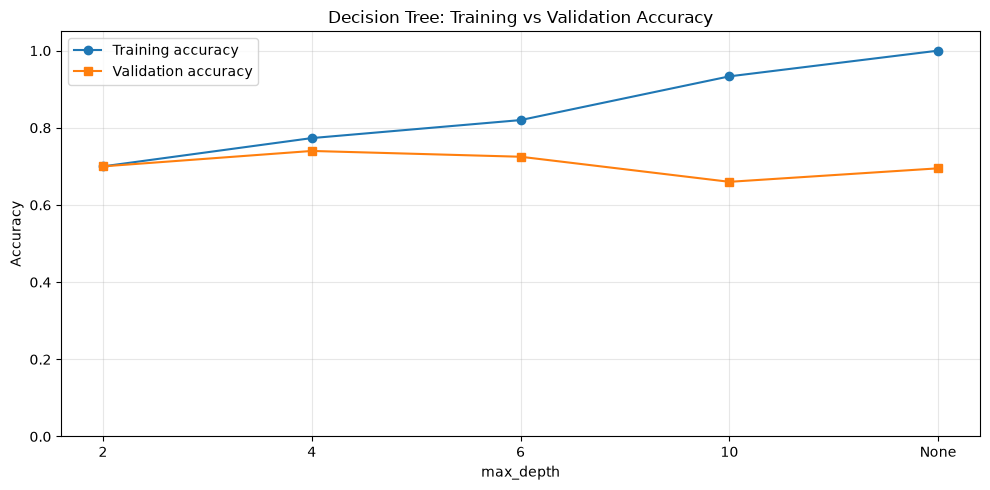

In [41]:
plot_df = results_df.copy()
plot_df["depth_label"] = plot_df["max_depth"]

x = np.arange(len(plot_df))

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    plot_df["training_accuracy"],
    marker="o",
    label="Training accuracy"
)

plt.plot(
    x,
    plot_df["validation_accuracy"],
    marker="s",
    label="Validation accuracy"
)

plt.xticks(x, plot_df["depth_label"])
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Validation Accuracy")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
unpruned_model = models[None]

y_train_pred = unpruned_model.predict(X_train)
y_val_pred = unpruned_model.predict(X_val)

train_accuracy = accuracy_score(y_train, y_train_pred)
val_accuracy = accuracy_score(y_val, y_val_pred)

unpruned_tree = unpruned_model.named_steps["tree"]

print("Unpruned tree analysis")
print("----------------------")
print(f"Training accuracy:   {train_accuracy:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Accuracy gap:        {train_accuracy - val_accuracy:.4f}")
print(f"Tree depth:          {unpruned_tree.get_depth()}")
print(f"Number of leaves:    {unpruned_tree.get_n_leaves()}")
print(f"Training samples:    {len(X_train)}")

Unpruned tree analysis
----------------------
Training accuracy:   1.0000
Validation accuracy: 0.6950
Accuracy gap:        0.3050
Tree depth:          17
Number of leaves:    143
Training samples:    600


In [43]:
best_idx = results_df["validation_accuracy"].idxmax()
best_depth = results_df.loc[best_idx, "max_depth"]

gap_idx = results_df["accuracy_gap"].idxmax()
largest_gap_depth = results_df.loc[gap_idx, "max_depth"]

print("Best depth by validation accuracy:", best_depth)
print(
    "Best validation accuracy:",
    round(results_df.loc[best_idx, "validation_accuracy"], 4)
)

print("\nLargest train-validation gap at depth:", largest_gap_depth)
print(
    "Largest gap:",
    round(results_df.loc[gap_idx, "accuracy_gap"], 4)
)

Best depth by validation accuracy: 4
Best validation accuracy: 0.74

Largest train-validation gap at depth: None
Largest gap: 0.305


In [44]:
selected_depth = next(
    depth for depth in depths if str(depth) == best_depth
)

best_model = models[selected_depth]

y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Selected max_depth:", selected_depth)
print(f"Test accuracy: {test_accuracy:.4f}")

Selected max_depth: 4
Test accuracy: 0.6550


In [45]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import export_text
from sklearn.metrics import accuracy_score

In [46]:
param_grid = {
    "tree__max_depth": [3, 5, 7, 10],
    "tree__min_samples_split": [2, 5, 10, 20]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Parameter combinations:", 16)
print("Cross-validation folds:", cv.get_n_splits())

Parameter combinations: 16
Cross-validation folds: 5


In [47]:
base_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(random_state=42))
])

grid_search = GridSearchCV(
    estimator=base_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest 5-fold CV accuracy:")
print(round(grid_search.best_score_, 4))

Best parameters:
{'tree__max_depth': 5, 'tree__min_samples_split': 2}

Best 5-fold CV accuracy:
0.71


In [48]:
cv_results = pd.DataFrame(grid_search.cv_results_)

results_table = cv_results[[
    "param_tree__max_depth",
    "param_tree__min_samples_split",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

results_table = results_table.rename(columns={
    "param_tree__max_depth": "max_depth",
    "param_tree__min_samples_split": "min_samples_split",
    "mean_train_score": "mean_train_accuracy",
    "mean_test_score": "mean_cv_accuracy",
    "std_test_score": "std_cv_accuracy",
    "rank_test_score": "rank"
})

print(
    results_table
    .sort_values(["rank", "std_cv_accuracy"])
    .round(4)
    .to_string(index=False)
)

 max_depth  min_samples_split  mean_train_accuracy  mean_cv_accuracy  std_cv_accuracy  rank
         5                  2               0.8150            0.7100           0.0481     1
         5                  5               0.8125            0.7100           0.0501     1
         5                 20               0.7971            0.7100           0.0533     3
         5                 10               0.8071            0.7000           0.0522     4
         7                 20               0.8254            0.6800           0.0455     5
         7                  5               0.8671            0.6700           0.0397     6
         3                 20               0.7413            0.6683           0.0193     7
         7                  2               0.8767            0.6683           0.0378     7
         3                  2               0.7421            0.6617           0.0251     9
         3                  5               0.7421            0.6617           0

In [49]:
best_model = grid_search.best_estimator_

y_val_tuned = best_model.predict(X_val)
validation_accuracy = accuracy_score(y_val, y_val_tuned)

print("Best parameters:", grid_search.best_params_)
print(f"Best mean CV accuracy: {grid_search.best_score_:.4f}")
print(f"Validation accuracy:   {validation_accuracy:.4f}")

Best parameters: {'tree__max_depth': 5, 'tree__min_samples_split': 2}
Best mean CV accuracy: 0.7100
Validation accuracy:   0.7450


Best tree depth: 5
Number of leaves: 25


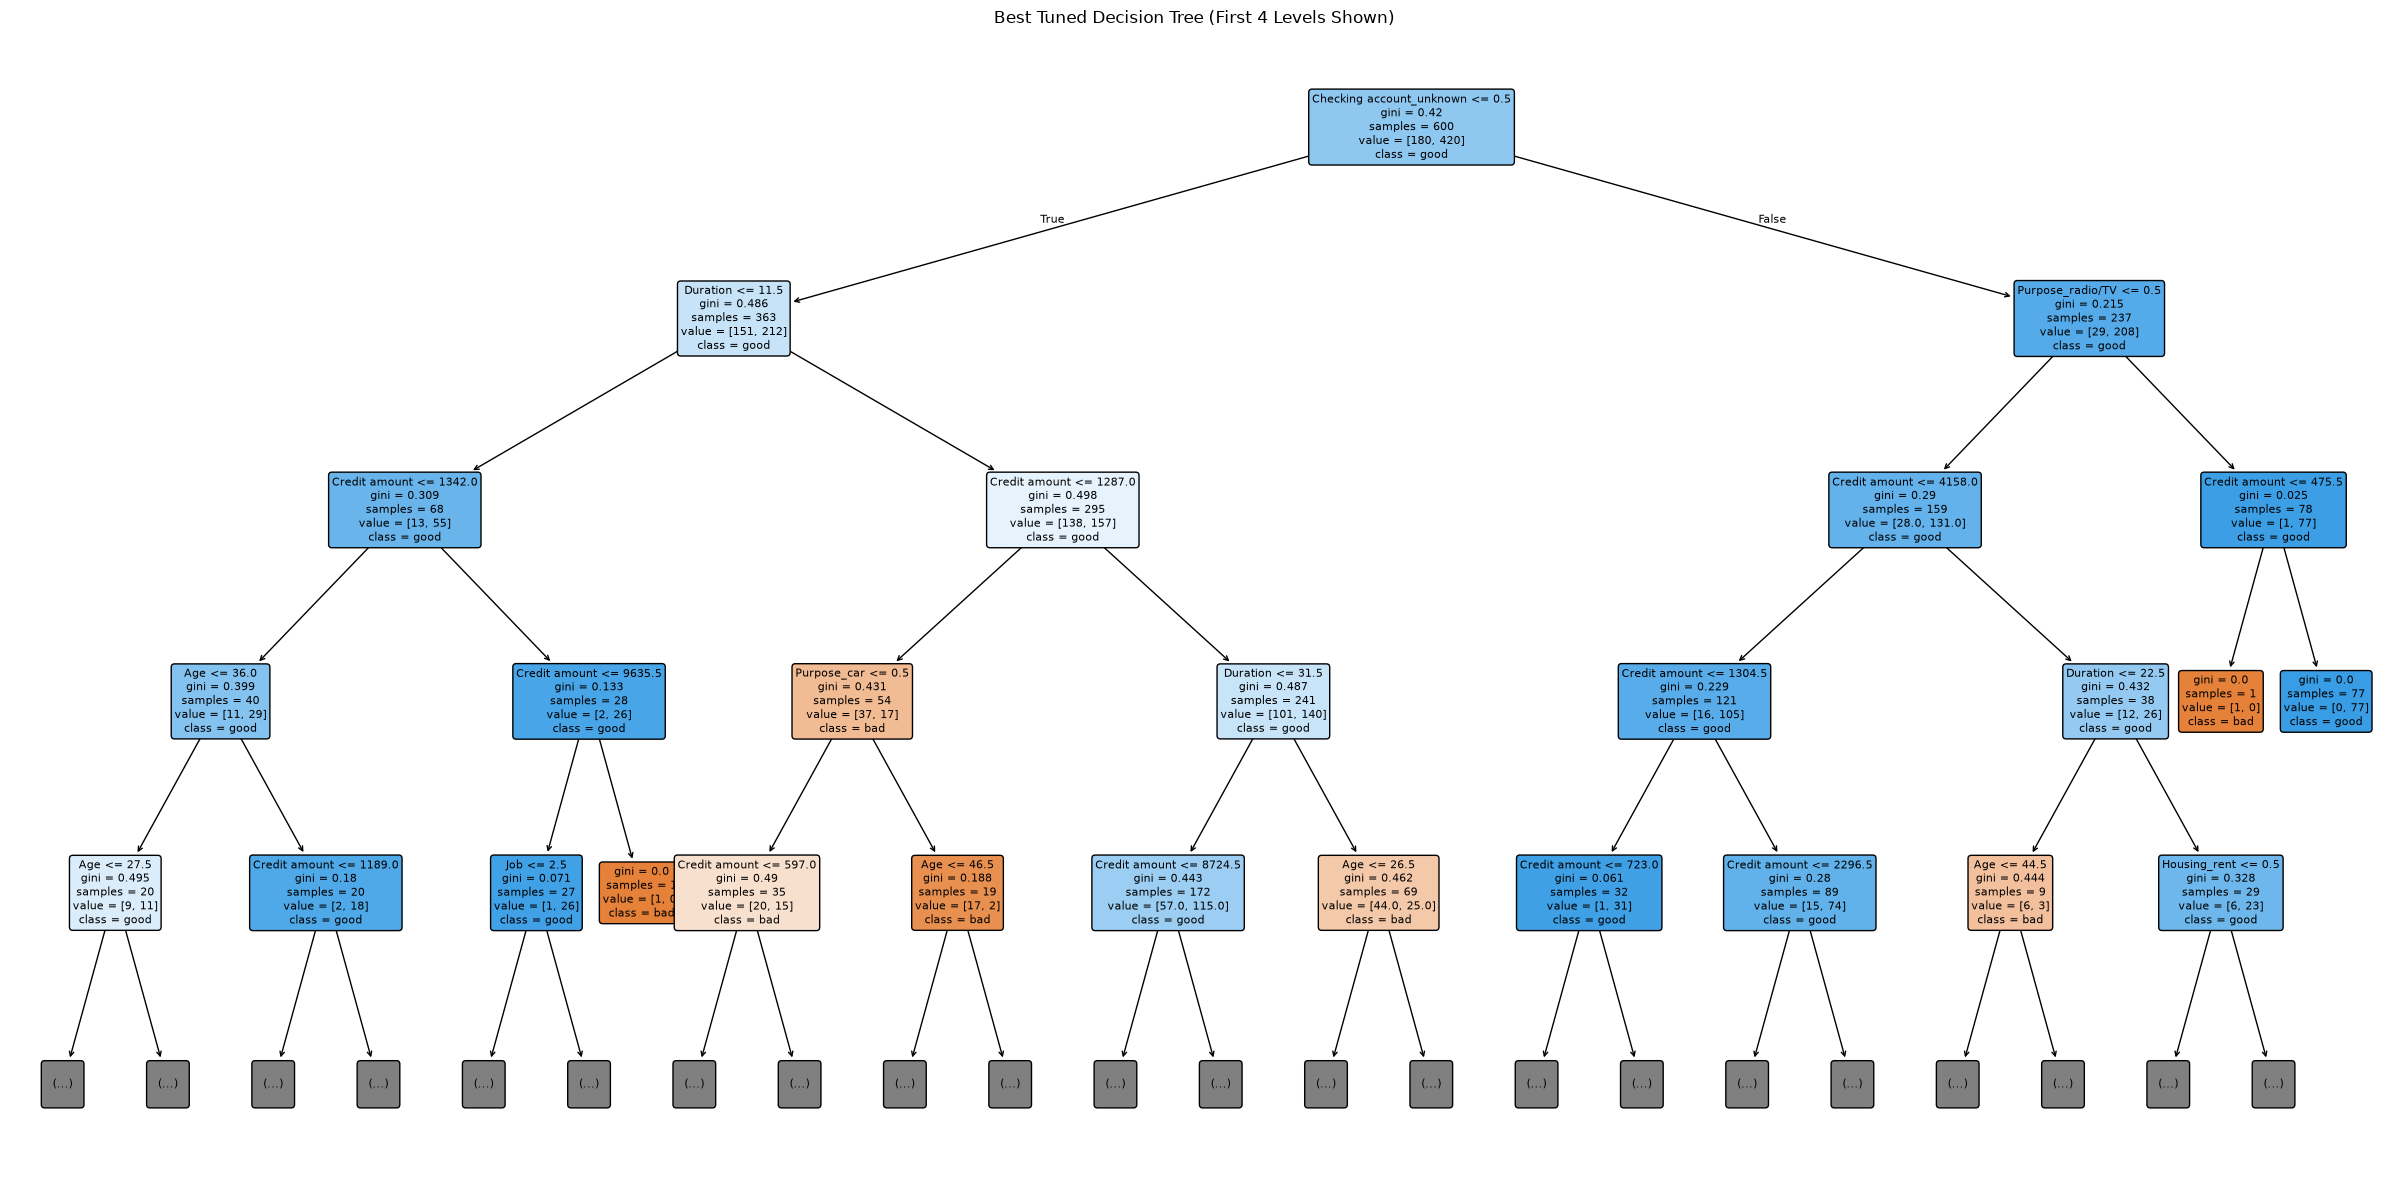

In [50]:
best_preprocessor = best_model.named_steps["preprocessor"]
best_tree = best_model.named_steps["tree"]

feature_names = best_preprocessor.get_feature_names_out()
class_names = [str(c) for c in best_tree.classes_]

print("Best tree depth:", best_tree.get_depth())
print("Number of leaves:", best_tree.get_n_leaves())

plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=8
)

plt.title("Best Tuned Decision Tree (First 4 Levels Shown)")
plt.tight_layout()
plt.show()

In [51]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_tree.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.head(15).round(4).to_string(index=False))

                 Feature  Importance
Checking account_unknown      0.2821
           Credit amount      0.2658
                Duration      0.2351
                     Age      0.1296
        Purpose_radio/TV      0.0318
             Purpose_car      0.0294
            Housing_rent      0.0213
                     Job      0.0049
                Sex_male      0.0000
              Sex_female      0.0000
  Saving accounts_little      0.0000
             Housing_own      0.0000
            Housing_free      0.0000
Saving accounts_moderate      0.0000
 Saving accounts_unknown      0.0000


In [52]:
def extract_leaf_rules(classifier, feature_names):
    tree_structure = classifier.tree_
    rules = []

    bad_class_index = list(classifier.classes_).index("bad")

    def traverse(node, conditions):
        left_child = tree_structure.children_left[node]
        right_child = tree_structure.children_right[node]

        # Leaf node
        if left_child == right_child:
            counts = tree_structure.value[node][0]
            total = counts.sum()

            bad_rate = (
                counts[bad_class_index] / total if total > 0 else 0
            )

            rules.append({
                "leaf_id": node,
                "conditions": conditions.copy(),
                "samples": int(tree_structure.n_node_samples[node]),
                "predicted_class": classifier.classes_[np.argmax(counts)],
                "bad_rate": bad_rate
            })
            return

        feature_index = tree_structure.feature[node]
        threshold = tree_structure.threshold[node]
        feature = feature_names[feature_index]

        traverse(
            left_child,
            conditions + [{
                "feature": feature,
                "operator": "<=",
                "threshold": threshold
            }]
        )

        traverse(
            right_child,
            conditions + [{
                "feature": feature,
                "operator": ">",
                "threshold": threshold
            }]
        )

    traverse(0, [])

    return rules


leaf_rules = extract_leaf_rules(best_tree, feature_names)

top_rules = sorted(
    leaf_rules,
    key=lambda rule: (rule["bad_rate"], rule["samples"]),
    reverse=True
)[:5]

for i, rule in enumerate(top_rules, start=1):
    print(f"\nRULE {i}")
    print("Conditions:")

    for condition in rule["conditions"]:
        print(
            f"  {condition['feature']} "
            f"{condition['operator']} "
            f"{condition['threshold']:.3f}"
        )

    print("Training samples:", rule["samples"])
    print("Predicted class:", rule["predicted_class"])
    print(f"Bad-risk proportion in leaf: {rule['bad_rate']:.2%}")


RULE 1
Conditions:
  Checking account_unknown <= 0.500
  Duration > 11.500
  Credit amount <= 1287.000
  Purpose_car > 0.500
  Age <= 46.500
Training samples: 16
Predicted class: bad
Bad-risk proportion in leaf: 100.00%

RULE 2
Conditions:
  Checking account_unknown <= 0.500
  Duration > 11.500
  Credit amount > 1287.000
  Duration <= 31.500
  Credit amount > 8724.500
Training samples: 5
Predicted class: bad
Bad-risk proportion in leaf: 100.00%

RULE 3
Conditions:
  Checking account_unknown <= 0.500
  Duration <= 11.500
  Credit amount > 1342.000
  Credit amount > 9635.500
Training samples: 1
Predicted class: bad
Bad-risk proportion in leaf: 100.00%

RULE 4
Conditions:
  Checking account_unknown > 0.500
  Purpose_radio/TV > 0.500
  Credit amount <= 475.500
Training samples: 1
Predicted class: bad
Bad-risk proportion in leaf: 100.00%

RULE 5
Conditions:
  Checking account_unknown > 0.500
  Purpose_radio/TV <= 0.500
  Credit amount > 4158.000
  Duration <= 22.500
  Age <= 44.500
Trainin

In [53]:
def explain_condition(condition):
    feature = condition["feature"]
    operator = condition["operator"]
    threshold = condition["threshold"]

    # Decode one-hot categorical features
    for original_col in categorical_features:
        prefix = original_col + "_"

        if feature.startswith(prefix):
            category = feature[len(prefix):]

            if operator == ">" and threshold < 1:
                return f"{original_col} is '{category}'"

            if operator == "<=" and threshold < 1:
                return f"{original_col} is NOT '{category}'"

    # Numeric features
    if operator == "<=":
        return f"{feature} is at most {threshold:.2f}"

    return f"{feature} is greater than {threshold:.2f}"


for i, rule in enumerate(top_rules, start=1):
    print(f"\nRule {i} — Predicted {rule['predicted_class']}")
    print("IF")

    for j, condition in enumerate(rule["conditions"]):
        phrase = explain_condition(condition)

        if j > 0:
            print("AND")

        print("  " + phrase)

    print(f"THEN predict: {rule['predicted_class']}")
    print(f"Training customers in this leaf: {rule['samples']}")
    print(f"Observed bad-risk proportion: {rule['bad_rate']:.1%}")


Rule 1 — Predicted bad
IF
  Checking account is NOT 'unknown'
AND
  Duration is greater than 11.50
AND
  Credit amount is at most 1287.00
AND
  Purpose is 'car'
AND
  Age is at most 46.50
THEN predict: bad
Training customers in this leaf: 16
Observed bad-risk proportion: 100.0%

Rule 2 — Predicted bad
IF
  Checking account is NOT 'unknown'
AND
  Duration is greater than 11.50
AND
  Credit amount is greater than 1287.00
AND
  Duration is at most 31.50
AND
  Credit amount is greater than 8724.50
THEN predict: bad
Training customers in this leaf: 5
Observed bad-risk proportion: 100.0%

Rule 3 — Predicted bad
IF
  Checking account is NOT 'unknown'
AND
  Duration is at most 11.50
AND
  Credit amount is greater than 1342.00
AND
  Credit amount is greater than 9635.50
THEN predict: bad
Training customers in this leaf: 1
Observed bad-risk proportion: 100.0%

Rule 4 — Predicted bad
IF
  Checking account is 'unknown'
AND
  Purpose is 'radio/TV'
AND
  Credit amount is at most 475.50
THEN predict

In [54]:
segment_rows = []

for i, rule in enumerate(top_rules, start=1):
    segment_rows.append({
        "Rule": i,
        "Conditions": " AND ".join(
            explain_condition(c) for c in rule["conditions"]
        ),
        "Training samples": rule["samples"],
        "Predicted risk": rule["predicted_class"],
        "Observed bad-risk %": round(rule["bad_rate"] * 100, 2)
    })

segments_df = pd.DataFrame(segment_rows)

print(segments_df.to_string(index=False))

 Rule                                                                                                                                                                             Conditions  Training samples Predicted risk  Observed bad-risk %
    1                                Checking account is NOT 'unknown' AND Duration is greater than 11.50 AND Credit amount is at most 1287.00 AND Purpose is 'car' AND Age is at most 46.50                16            bad               100.00
    2 Checking account is NOT 'unknown' AND Duration is greater than 11.50 AND Credit amount is greater than 1287.00 AND Duration is at most 31.50 AND Credit amount is greater than 8724.50                 5            bad               100.00
    3                                    Checking account is NOT 'unknown' AND Duration is at most 11.50 AND Credit amount is greater than 1342.00 AND Credit amount is greater than 9635.50                 1            bad               100.00
    4                       

In [55]:
from sklearn.metrics import classification_report, confusion_matrix

y_test_tuned = best_model.predict(X_test)

print("Best parameters:", grid_search.best_params_)
print(f"Mean 5-fold CV accuracy: {grid_search.best_score_:.4f}")
print(f"Validation accuracy: {validation_accuracy:.4f}")
print(f"Test accuracy: {accuracy_score(y_test, y_test_tuned):.4f}")

print("\nConfusion matrix (labels: bad, good):")
print(confusion_matrix(y_test, y_test_tuned, labels=["bad", "good"]))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_tuned,
    labels=["bad", "good"],
    zero_division=0
))

Best parameters: {'tree__max_depth': 5, 'tree__min_samples_split': 2}
Mean 5-fold CV accuracy: 0.7100
Validation accuracy: 0.7450
Test accuracy: 0.6650

Confusion matrix (labels: bad, good):
[[ 20  40]
 [ 27 113]]

Classification report:
              precision    recall  f1-score   support

         bad       0.43      0.33      0.37        60
        good       0.74      0.81      0.77       140

    accuracy                           0.67       200
   macro avg       0.58      0.57      0.57       200
weighted avg       0.64      0.67      0.65       200

